# Практическая работа №3. Сингулярное разложение и кластерный анализ

In [20]:
import os
import time
from functools import wraps
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.linalg import svd
from scipy.special import logsumexp
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
from scipy.spatial.distance import pdist, cdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from threadpoolctl import threadpool_limits
try:
    import psutil
except ImportError:
    psutil = None
import ml_common as mc
try:
    from numba import njit
except ImportError:
    def njit(func): return func
    print("Numba не установлен: SGD будет работать без ускорения")

SEED = 42
TOP_N = 10
MAIN_COLOR = "#3987e5"
PALETTE = ["#3987e5", "#d95926", "#199e70", "#c98500", "#d55181", "#008300", "#9085e9", "#e66767"]
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2})
# Не даём BLAS создавать десятки потоков на небольших матрицах.
blas_limit = threadpool_limits(limits=2)
RESULT_DIR = mc.DATA_DIR / "work3_results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = RESULT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

def finish_figure(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

def measure_resources(func):
    @wraps(func)
    def wrapper(*args, **kwargs):
        process = psutil.Process(os.getpid()) if psutil is not None else None
        start = time.perf_counter()
        before = process.memory_info().rss / 1024**2 if process else None
        result = func(*args, **kwargs)
        after = process.memory_info().rss / 1024**2 if process else None
        memory = f"RSS {after:.1f} MB, изменение {after-before:+.1f} MB" if process else "RSS недоступно (psutil не установлен)"
        print(f"{func.__name__}: {time.perf_counter()-start:.2f} с; {memory}")
        return result
    return wrapper


Numba не установлен: SGD будет работать без ускорения


# Загрузка и схема проверки

In [2]:
data = mc.load_slice()
required = {"train", "test", "movies"}
if not required.issubset(data):
    raise FileNotFoundError("Нет data/ml_slice/{train,test,movies}.csv. Сначала выполните 00_data_preparation.ipynb.")
train_full, test, movies = data["train"], data["test"], data["movies"]
train_fit, valid = mc.temporal_split(train_full, test_ratio=0.2)
user_ids = np.sort(train_full["userId"].unique())
movie_ids = np.sort(movies["movieId"].unique())
user_index, movie_index = pd.Index(user_ids), pd.Index(movie_ids)
movie_info = movies.set_index("movieId").loc[movie_ids]
n_users, n_movies = len(user_ids), len(movie_ids)
assert not train_full.duplicated(["userId", "movieId"]).any()
assert set(test["userId"]).issubset(set(user_ids))
for label, frame in [("train_fit", train_fit), ("valid", valid), ("train_full", train_full), ("test", test)]:
    print(f"{label}: {len(frame):,} оценок")
print(f"Матрица: {n_users} × {n_movies}; плотность train: {len(train_full)/(n_users*n_movies):.2%}")


train_fit: 112,064 оценок
valid: 27,990 оценок
train_full: 140,054 оценок
test: 35,018 оценок
Матрица: 1988 × 2191; плотность train: 3.22%


# Матрица оценок и ориентиры

$R_{ui}$ - оценка, $M_{ui}$ - маска известных оценок. Ноль в $R$ обозначает **пропуск**, а не отрицательную оценку.

Сначала оцениваем базовую модель $b_{ui}=\mu+b_u+b_i$ с регуляризованными смещениями. Для обычного SVD строим матрицу остатков $A=M\odot(R-b)$; пропуски остатков заполняем нулём. Это эквивалентно заполнению неизвестных **оценок базовым прогнозом**, а не нулём. Все средние и смещения считаются только по обучающей части.

Обычное SVD оптимизирует восстановление всей заполненной матрицы. Funk SVD и SVD++ оптимизируют ошибку **только на известных оценках** - эти задачи различаются.


In [3]:
def pairs(frame):
    u = user_index.get_indexer(frame["userId"])
    i = movie_index.get_indexer(frame["movieId"])
    if (u < 0).any() or (i < 0).any():
        raise ValueError("Обнаружены идентификаторы вне общего среза")
    return u, i, frame["rating"].to_numpy(float)


def prepare(frame, bias_reg=10.0):
    u, i, y = pairs(frame)
    R = np.zeros((n_users, n_movies))
    R[u, i] = y
    M = R > 0
    mu = float(y.mean())
    bu, bi = np.zeros(n_users), np.zeros(n_movies)
    # Попеременно уточняем смещения; в каждой сумме участвуют только известные оценки.
    for _ in range(10):
        bi = np.bincount(i, weights=y-mu-bu[u], minlength=n_movies) / (bias_reg + np.bincount(i, minlength=n_movies))
        bu = np.bincount(u, weights=y-mu-bi[i], minlength=n_users) / (bias_reg + np.bincount(u, minlength=n_users))
    H = sparse.csr_matrix((np.ones(len(y)), (u, i)), shape=R.shape)
    norm = np.sqrt(np.asarray(H.sum(axis=1)).ravel())
    H = sparse.diags(1 / np.maximum(norm, 1)) @ H
    return {"R": R, "M": M, "mu": mu, "bu": bu, "bi": bi,
            "H": H.tocsr(), "u": u, "i": i, "y": y,
            "popularity": ((R >= mc.RELEVANCE_THRESHOLD) & M).sum(axis=0)}


def effective_users(model, phase):
    return model["P"] + phase["H"] @ model["Y"] if model["kind"] == "SVD++" else model["P"]


def predict_pairs(model, phase, frame):
    u, i, _ = pairs(frame)
    z = effective_users(model, phase)
    return model["mu"] + model["bu"][u] + model["bi"][i] + np.einsum("ij,ij->i", z[u], model["Q"][i])


def score_matrix(model, phase):
    return model["mu"] + model["bu"][:, None] + model["bi"][None, :] + effective_users(model, phase) @ model["Q"].T


def error_metrics(y, predictions):
    # Одна и та же шкала для всех методов; raw-ошибки отдельно сохраняются при обучении.
    p = np.clip(predictions, 0.5, 5.0)
    return {"MSE": float(np.mean((y-p)**2)), "MAE": mc.mae(y, p), "RMSE": mc.rmse(y, p)}


def recommendations(scores, phase, n=TOP_N):
    n = min(n, scores.shape[1])
    # Ранжируем необрезанные прогнозы, чтобы отсечение на 5 не создавало ничьи.
    scores = np.where(phase["M"], -np.inf, scores)
    order = np.argsort(-scores, axis=1, kind="stable")[:, :n]
    return {user_ids[u]: [movie_ids[j] for j in order[u] if np.isfinite(scores[u, j])]
            for u in range(len(user_ids))}


def evaluate(model, phase, frame):
    _, _, y = pairs(frame)
    recs = recommendations(score_matrix(model, phase), phase)
    row = error_metrics(y, predict_pairs(model, phase, frame))
    ranking = mc.ranking_metrics(recs, frame, k=TOP_N)
    ranking.pop("users")
    row.update(ranking)
    recommended: set[int] = {
        int(movie_id)
        for user_id in frame["userId"].unique()
        for movie_id in recs[user_id]
    }
    row["Покрытие каталога"] = len(recommended) / n_movies
    return row, recs


def svd_model(phase, U, s, Vt, rank):
    rank = min(rank, len(s))
    root = np.sqrt(s[:rank])
    return {"kind": "SVD", "mu": phase["mu"], "bu": phase["bu"].copy(), "bi": phase["bi"].copy(),
            "P": U[:, :rank] * root, "Q": Vt[:rank].T * root, "rank": rank}


@measure_resources
def decompose(phase):
    A = np.where(phase["M"], phase["R"]-phase["mu"]-phase["bu"][:, None]-phase["bi"], 0.0)
    U, s, Vt = svd(A, full_matrices=False, check_finite=True)
    return A, U, s, Vt


                       MSE     MAE    RMSE
Метод                                     
Глобальное среднее  1.0835  0.7896  1.0409
Смещения            0.6922  0.6150  0.8320
Популярное: {'Precision@10': 0.06479166666666666, 'Recall@10': 0.08863623584704042, 'NDCG@10': 0.09368493252544804, 'users': 1920}


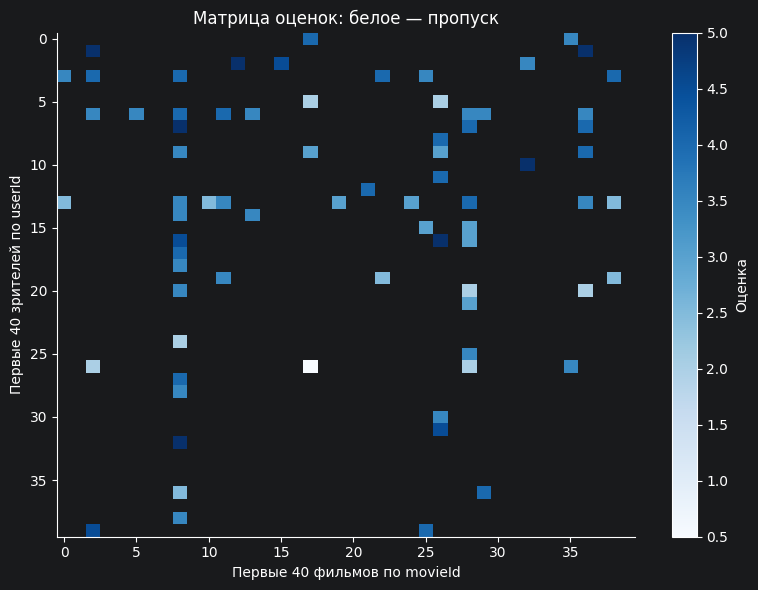

In [4]:
fit, full = prepare(train_fit), prepare(train_full)
u_test, i_test, y_test = pairs(test)
baseline_rows = []
for name, pred in [("Глобальное среднее", np.full(len(test), full["mu"])),
                   ("Смещения", full["mu"]+full["bu"][u_test]+full["bi"][i_test])]:
    baseline_rows.append({"Метод": name, **error_metrics(y_test, pred)})
popular_recs = recommendations(np.tile(full["popularity"], (n_users, 1)), full)
popular_metrics = mc.ranking_metrics(popular_recs, test, k=TOP_N)
print(pd.DataFrame(baseline_rows).set_index("Метод").round(4).to_string())
print("Популярное:", popular_metrics)
plt.figure(figsize=(8, 6))
plt.imshow(np.where(full["M"][:40, :40], full["R"][:40, :40], np.nan), cmap="Blues", vmin=.5, vmax=5, aspect="auto")
plt.colorbar(label="Оценка")
plt.xlabel("Первые 40 фильмов по movieId"); plt.ylabel("Первые 40 зрителей по userId")
plt.title("Матрица оценок: белое - пропуск"); plt.grid(False)
finish_figure("01_rating_matrix")


# Сингулярное разложение

$A=UDV^T$, где $U^TU=I$, $V^TV=I$, $D=\operatorname{diag}(\sigma_1,\ldots)$, $\sigma_1\ge\sigma_2\ge0$.
Сохраняем $k$ факторов: $A_k=U_kD_kV_k^T$. Представления зрителей $P=U_k\sqrt{D_k}$, фильмов $Q=V_k\sqrt{D_k}$ дают $A_k=PQ^T$ и прогноз $\hat r_{ui}=b_{ui}+p_u^Tq_i$.

Сингулярное значение характеризует вклад фактора **в восстановление матрицы остатков**. Доля энергии $\sigma_f^2/\sum_j\sigma_j^2$ не является ни точностью рекомендаций, ни долей объяснённого вкуса. Ранг выбираем по MAE на валидации, а не только по энергии.


decompose: 3.24 с; RSS 489.8 MB, изменение +119.6 MB
 rank    MSE    MAE   RMSE
    5 0.6989 0.6159 0.8360
   10 0.6962 0.6145 0.8344
   20 0.6952 0.6135 0.8338
   40 0.6979 0.6151 0.8354
Выбранный ранг: 20


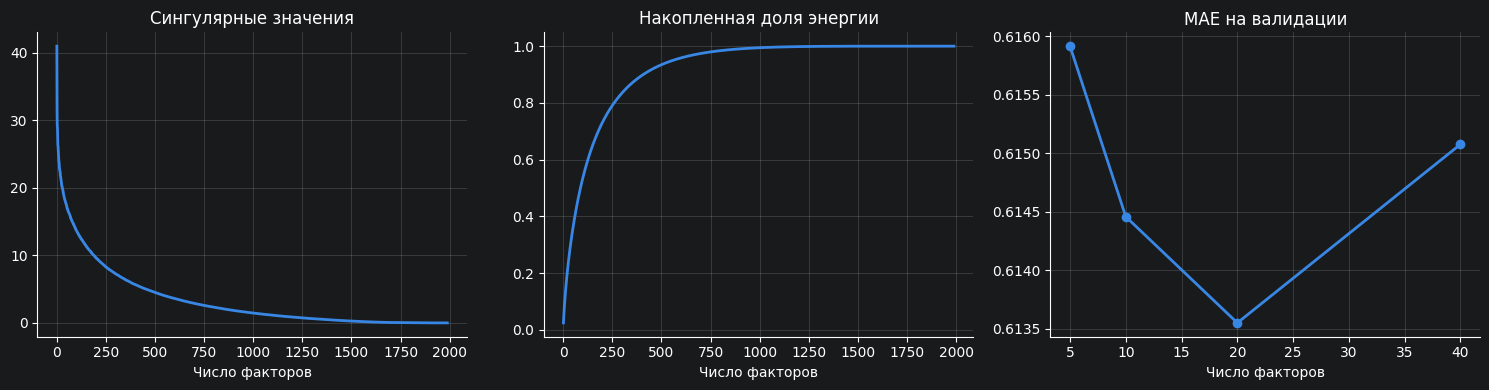

In [5]:
A_fit, U_fit, s_fit, Vt_fit = decompose(fit)
RANK_GRID = sorted({min(k, min(A_fit.shape)) for k in [5, 10, 20, 40]})
svd_rows = []
for k in RANK_GRID:
    model = svd_model(fit, U_fit, s_fit, Vt_fit, k)
    svd_rows.append({"rank": k, **error_metrics(valid["rating"].to_numpy(), predict_pairs(model, fit, valid))})
svd_tuning = pd.DataFrame(svd_rows)
best_rank = int(svd_tuning.loc[svd_tuning["MAE"].idxmin(), "rank"])
print(svd_tuning.round(4).to_string(index=False)); print("Выбранный ранг:", best_rank)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(np.arange(1, len(s_fit)+1), s_fit, color=MAIN_COLOR); axes[0].set_title("Сингулярные значения")
axes[1].plot(np.arange(1, len(s_fit)+1), np.cumsum(s_fit**2)/np.sum(s_fit**2), color=MAIN_COLOR)
axes[1].set_title("Накопленная доля энергии")
axes[2].plot(svd_tuning["rank"], svd_tuning["MAE"], "o-", color=MAIN_COLOR); axes[2].set_title("MAE на валидации")
for ax in axes: ax.set_xlabel("Число факторов")
finish_figure("02_svd_rank")
svd_tuning.to_csv(RESULT_DIR / "svd_tuning.csv", index=False)
# Полное разложение должно восстановить именно A, а не неизвестные истинные оценки.
assert np.allclose((U_fit*s_fit) @ Vt_fit, A_fit, atol=1e-8)
assert np.allclose(U_fit.T @ U_fit, np.eye(len(s_fit)), atol=1e-8)


# Дополнительно: Funk SVD и SVD++

**Funk SVD** - обучаемая низкоранговая факторизация известных оценок, а не вызов обычного SVD заполненной матрицы:
$$\hat r_{ui}=\mu+b_u+b_i+p_u^Tq_i.$$

**SVD++** дополнительно учитывает $N(u)$ - все фильмы, которые зритель оценил в обучающей части, независимо от величины оценки:
$$z_u=p_u+|N(u)|^{-1/2}\sum_{j\in N(u)}y_j,\qquad \hat r_{ui}=\mu+b_u+b_i+z_u^Tq_i.$$
Явный сигнал - величина оценки. Неявный - факт взаимодействия; низкая оценка тоже входит в $N(u)$. Тестовые и валидационные взаимодействия при обучении не используются. SVD++ не превращаем в другую модель для исключительно бинарных данных.

Для обоих методов минимизируем
$$J=\frac{1}{2|K|}\left[\sum_{(u,i)\in K}(\hat r_{ui}-r_{ui})^2+\lambda(\|P\|_F^2+\|Q\|_F^2+\|b_u\|^2+\|b_i\|^2+[\|Y\|_F^2])\right].$$
Слагаемое $Y$ есть только у SVD++. Funk SVD обучается **поэлементным SGD** с перемешиванием известных оценок в каждой эпохе. Обновления реализованы вручную; Numba при наличии лишь ускоряет тот же код. Регуляризация параметра при каждом взаимодействии делится на число его обучающих наблюдений: за эпоху это даёт штраф именно из приведённой общей функции ошибки, а не незаявленный штраф, зависящий от популярности.

Для SVD++ используем полный градиент и Adam. Градиент по $Y$ равен $H^T(EQ)+\lambda Y$, где $H_{uj}=1/\sqrt{|N(u)|}$ на истории, а $E$ - разреженная матрица ошибок. Это позволяет обновлять неявные факторы без вложенного цикла по всей истории для каждой оценки. Оптимизатор реализован вручную.

После **каждой эпохи** измеряем ошибки по всем затронутым обучающим оценкам и по всей валидации, сохраняем лучший вариант. Остановка: малое улучшение валидационной MAE в течение нескольких эпох, нечисловая ошибка или предел эпох. Итоговое обучение на полном `train` длится ровно выбранное по валидации число эпох; тест не управляет остановкой.


In [6]:
@njit
def funk_sgd_epoch(P, Q, bu, bi, mu, u, i, y, order, count_u, count_i, reg, lr):
    for pos in order:
        a, b = u[pos], i[pos]
        old_p, old_q = P[a].copy(), Q[b].copy()
        error = mu+bu[a]+bi[b]+np.dot(old_p, old_q)-y[pos]
        bu[a] -= lr*(error+reg*bu[a]/count_u[a])
        bi[b] -= lr*(error+reg*bi[b]/count_i[b])
        P[a] -= lr*(error*old_q+reg*old_p/count_u[a])
        Q[b] -= lr*(error*old_p+reg*old_q/count_i[b])


def mf_gradients(model, phase, reg):
    P, Q, bu, bi = model["P"], model["Q"], model["bu"], model["bi"]
    u, i, y = phase["u"], phase["i"], phase["y"]
    z = effective_users(model, phase)
    e = model["mu"]+bu[u]+bi[i]+np.einsum("ij,ij->i", z[u], Q[i])-y
    E = sparse.csr_matrix((e, (u, i)), shape=phase["R"].shape)
    g_z = E @ Q
    grads = {"P": g_z+reg*P, "Q": E.T @ z+reg*Q,
             "bu": np.bincount(u, weights=e, minlength=len(bu))+reg*bu,
             "bi": np.bincount(i, weights=e, minlength=len(bi))+reg*bi}
    if model["kind"] == "SVD++":
        grads["Y"] = phase["H"].T @ g_z+reg*model["Y"]
    penalty = sum(float(np.sum(model[key]**2)) for key in grads)
    loss = (float(e@e)+reg*penalty)/(2*len(y))
    return loss, {key: value/len(y) for key, value in grads.items()}, e


def fit_mf(phase, rank, reg, kind="Funk SVD", validation=None, epochs=120,
           learning_rate=None, patience=10, min_delta=1e-4, seed=SEED):
    rng = np.random.default_rng(seed)
    model = {"kind": kind, "rank": rank, "reg": reg, "mu": phase["mu"],
             "bu": phase["bu"].copy(), "bi": phase["bi"].copy(),
             "P": rng.normal(0, .05, (n_users, rank)), "Q": rng.normal(0, .05, (n_movies, rank))}
    # Фильм без обучающих оценок не получает случайный латентный прогноз.
    cold = ~phase["M"].any(axis=0)
    model["Q"][cold] = 0
    if kind == "SVD++":
        model["Y"] = rng.normal(0, .02, (n_movies, rank)); model["Y"][cold] = 0
    keys = ["P", "Q", "bu", "bi"] + (["Y"] if kind == "SVD++" else [])
    first = {key: np.zeros_like(model[key]) for key in keys}
    second = {key: np.zeros_like(model[key]) for key in keys}
    best, best_value, best_epoch, significant_best, stale = None, np.inf, 0, np.inf, 0
    history = []
    if learning_rate is None: learning_rate = .01 if kind == "Funk SVD" else .03
    count_u = np.maximum(np.bincount(phase["u"], minlength=n_users), 1)
    count_i = np.maximum(np.bincount(phase["i"], minlength=n_movies), 1)
    for epoch in range(1, epochs+1):
        if kind == "Funk SVD":
            funk_sgd_epoch(model["P"], model["Q"], model["bu"], model["bi"], model["mu"],
                           phase["u"], phase["i"], phase["y"], rng.permutation(len(phase["y"])),
                           count_u, count_i, reg, learning_rate)
        else:
            _, grads, _ = mf_gradients(model, phase, reg)
            for key in keys:
                g = grads[key]
                first[key] = .9*first[key]+.1*g
                second[key] = .999*second[key]+.001*g*g
                model[key] -= learning_rate*(first[key]/(1-.9**epoch))/(np.sqrt(second[key]/(1-.999**epoch))+1e-8)
        loss, _, e = mf_gradients(model, phase, reg)
        if not np.isfinite(loss):
            raise FloatingPointError(f"{kind}: нечисловая ошибка на эпохе {epoch}; уменьшите learning_rate")
        train_pred = phase["y"]+e
        row = {"epoch": epoch, "objective": loss,
               "train_raw_MSE": float(np.mean(e**2)),
               **{"train_"+key: value for key, value in error_metrics(phase["y"], train_pred).items()}}
        if validation is not None:
            v = predict_pairs(model, phase, validation)
            row.update({"valid_"+key: value for key, value in error_metrics(validation["rating"].to_numpy(), v).items()})
            row["valid_raw_MSE"] = float(np.mean((validation["rating"].to_numpy()-v)**2))
            value = row["valid_MAE"]
            if value < best_value:
                best_value, best_epoch = value, epoch
                best = {key: model[key].copy() for key in keys}
            if significant_best-value >= min_delta:
                significant_best, stale = value, 0
            else:
                stale += 1
        history.append(row)
        if validation is not None and stale >= patience:
            break
    if validation is not None:
        model.update(best)
    else:
        best_epoch = epochs
    model["best_epoch"] = best_epoch
    return model, pd.DataFrame(history)


## Проверка градиентов на маленькой матрице

Центральная конечная разность проверяет производные функции ошибки, включая вклад неявных факторов SVD++. Это проверка алгоритма; результаты на игрушечных данных не выдаются за качество на MovieLens.


In [7]:
toy = {"R": np.array([[5., 0., 2.], [0., 4., 3.]]),
       "u": np.array([0, 0, 1, 1]), "i": np.array([0, 2, 1, 2]), "y": np.array([5., 2., 4., 3.])}
toy["H"] = sparse.csr_matrix((toy["R"] > 0)/np.sqrt((toy["R"] > 0).sum(axis=1))[:, None])
toy_rng = np.random.default_rng(SEED)
for kind in ["Funk SVD", "SVD++"]:
    model = {"kind": kind, "mu": 3., "bu": np.zeros(2), "bi": np.zeros(3),
             "P": toy_rng.normal(0, .1, (2, 2)), "Q": toy_rng.normal(0, .1, (3, 2))}
    if kind == "SVD++": model["Y"] = toy_rng.normal(0, .1, (3, 2))
    _, grads, _ = mf_gradients(model, toy, 2.)
    max_diff = 0.
    for key, gradient in grads.items():
        for idx in np.ndindex(model[key].shape):
            old, eps = model[key][idx], 1e-6
            model[key][idx] = old+eps; plus = mf_gradients(model, toy, 2.)[0]
            model[key][idx] = old-eps; minus = mf_gradients(model, toy, 2.)[0]
            model[key][idx] = old
            max_diff = max(max_diff, abs((plus-minus)/(2*eps)-gradient[idx]))
    assert max_diff < 1e-6
    print(kind, "максимальная ошибка градиента:", f"{max_diff:.2e}")


Funk SVD максимальная ошибка градиента: 1.21e-10
SVD++ максимальная ошибка градиента: 1.15e-10


Funk SVD, k=10, lambda=0: MAE=0.6104, эпох=16
Funk SVD, k=10, lambda=2: MAE=0.6071, эпох=23
Funk SVD, k=10, lambda=10: MAE=0.6047, эпох=46
Funk SVD, k=20, lambda=0: MAE=0.6081, эпох=16
Funk SVD, k=20, lambda=2: MAE=0.6045, эпох=19
Funk SVD, k=20, lambda=10: MAE=0.6027, эпох=42
SVD++, k=10, lambda=0: MAE=0.6220, эпох=2
SVD++, k=10, lambda=2: MAE=0.6212, эпох=3
SVD++, k=10, lambda=10: MAE=0.6037, эпох=119
SVD++, k=20, lambda=0: MAE=0.6206, эпох=3
SVD++, k=20, lambda=2: MAE=0.6187, эпох=4
SVD++, k=20, lambda=10: MAE=0.6095, эпох=10
tune_models: 794.84 с; RSS 494.8 MB, изменение -0.9 MB
Выбранные параметры: {'Funk SVD': {'rank': 20, 'reg': 10.0, 'epochs': 42}, 'SVD++': {'rank': 10, 'reg': 10.0, 'epochs': 119}}


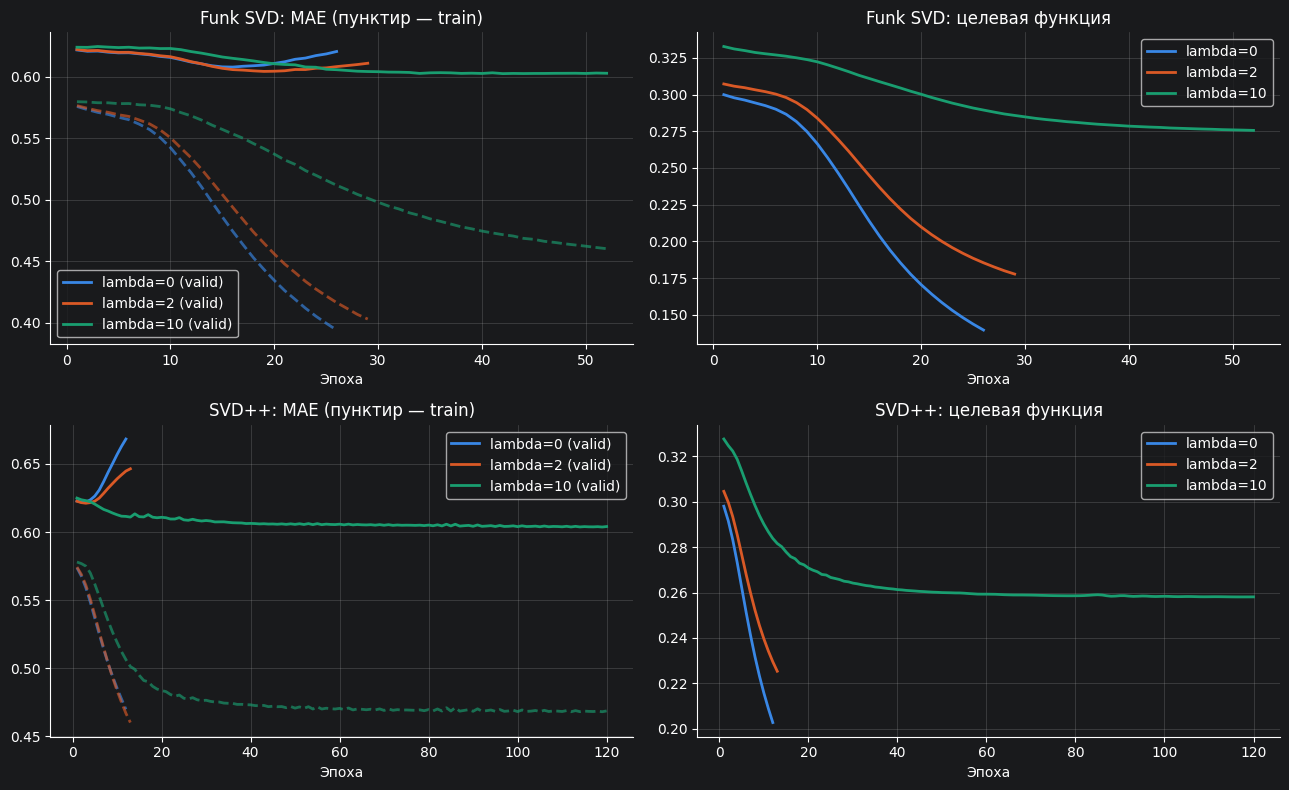

Эффект регуляризации оцениваем по valid, а не по уменьшению train-ошибки.


In [8]:
MF_RANKS = sorted({min(k, min(n_users, n_movies)) for k in [10, 20]})
REG_GRID = [0.0, 2.0, 10.0]
MAX_EPOCHS = 120
tuning_rows, histories = [], {}

@measure_resources
def tune_models():
    for kind in ["Funk SVD", "SVD++"]:
        for k in MF_RANKS:
            for reg in REG_GRID:
                model, history = fit_mf(fit, k, reg, kind, validation=valid, epochs=MAX_EPOCHS)
                row = {"Метод": kind, "rank": k, "reg": reg, "epochs": model["best_epoch"],
                       **error_metrics(valid["rating"].to_numpy(), predict_pairs(model, fit, valid))}
                tuning_rows.append(row); histories[(kind, k, reg)] = history
                print(f"{kind}, k={k}, lambda={reg:g}: MAE={row['MAE']:.4f}, эпох={row['epochs']}")

tune_models()
mf_tuning = pd.DataFrame(tuning_rows)
mf_tuning.to_csv(RESULT_DIR / "mf_tuning.csv", index=False)
best_configs = {}
for kind in ["Funk SVD", "SVD++"]:
    part = mf_tuning[mf_tuning["Метод"] == kind]
    # Для SVD++ итоговый метод обязательно регуляризован по условию задания.
    allowed = part[part["reg"] > 0] if kind == "SVD++" else part
    row = allowed.loc[allowed["MAE"].idxmin()]
    best_configs[kind] = {"rank": int(row["rank"]), "reg": float(row["reg"]), "epochs": int(row["epochs"])}
print("Выбранные параметры:", best_configs)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for r, kind in enumerate(["Funk SVD", "SVD++"]):
    config = best_configs[kind]
    for j, reg in enumerate(REG_GRID):
        h = histories[(kind, config["rank"], reg)]
        axes[r, 0].plot(h["epoch"], h["train_MAE"], color=PALETTE[j], linestyle="--", alpha=.65)
        axes[r, 0].plot(h["epoch"], h["valid_MAE"], color=PALETTE[j], label=f"lambda={reg:g} (valid)")
        axes[r, 1].plot(h["epoch"], h["objective"], color=PALETTE[j], label=f"lambda={reg:g}")
        h.to_csv(RESULT_DIR / f"history_{kind.replace(' ', '_').replace('+', 'p')}_{config['rank']}_{reg:g}.csv", index=False)
    axes[r, 0].set_title(f"{kind}: MAE (пунктир - train)")
    axes[r, 1].set_title(f"{kind}: целевая функция")
    for ax in axes[r]: ax.set_xlabel("Эпоха"); ax.legend()
finish_figure("03_learning_and_regularization")
print("Эффект регуляризации оцениваем по valid, а не по уменьшению train-ошибки.")


# Итоговые модели и проверка качества

Повторно обучаем выбранные модели на полном `train`. Сравниваем MSE, MAE, RMSE, Precision@10, Recall@10, NDCG@10 и покрытие каталога. Для сравнения с работами №1–2 можно использовать их CSV, если они лежат рядом; различие в малых долях метрик само по себе не доказывает превосходство.


decompose: 4.48 с; RSS 752.0 MB, изменение +97.0 MB
             MSE     MAE    RMSE  Precision@10  Recall@10  NDCG@10  Покрытие каталога
Метод                                                                                
SVD       0.6734  0.6053  0.8206        0.0335     0.0451   0.0451             0.0707
Funk SVD  0.6524  0.5960  0.8077        0.0493     0.0633   0.0639             0.1269
SVD++     0.6414  0.5927  0.8009        0.0422     0.0566   0.0594             0.1935
Ориентиры:
             Метод    MSE    MAE   RMSE
Глобальное среднее 1.0835 0.7896 1.0409
          Смещения 0.6922 0.6150 0.8320


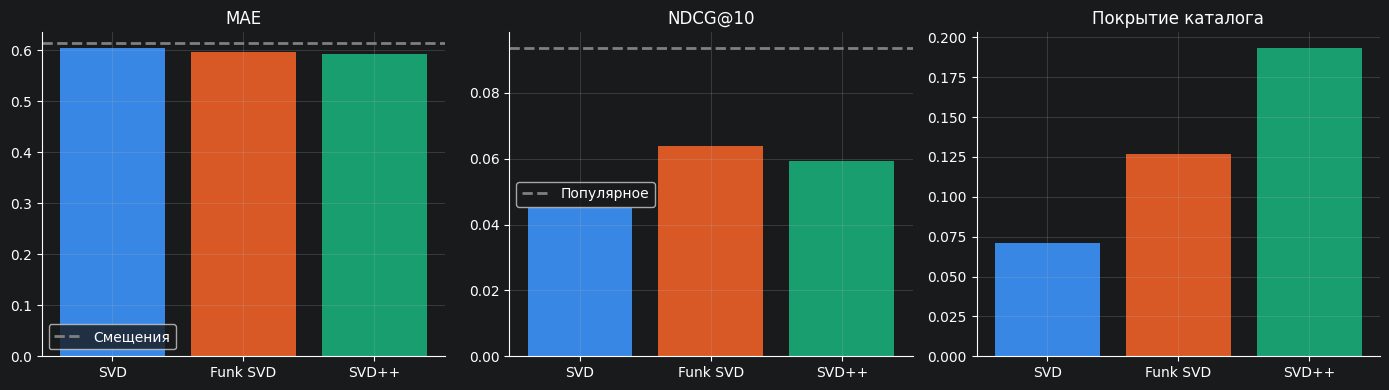

Результаты предыдущей работы (work1_results.csv):
                                       k прогноз  k топ-N     MAE    RMSE  Покрытие прогноза  Precision@10  Recall@10  NDCG@10  Покрытие каталога
Метод                                                                                                                                            
Глобальное среднее                           NaN      NaN  0.7896  1.0409             1.0000           NaN        NaN      NaN                NaN
Среднее пользователя                         NaN      NaN  0.6680  0.8976             1.0000           NaN        NaN      NaN                NaN
Среднее фильма                               NaN      NaN  0.7422  0.9843             1.0000           NaN        NaN      NaN                NaN
Смещения mu + b_u + b_i                      NaN      NaN  0.6188  0.8336             1.0000           NaN        NaN      NaN                NaN
Популярное                                   NaN      NaN     NaN     NaN 

In [21]:
A_full, U_full, s_full, Vt_full = decompose(full)
models = {"SVD": svd_model(full, U_full, s_full, Vt_full, best_rank)}
for kind, config in best_configs.items():
    models[kind], final_history = fit_mf(full, kind=kind, **config)
    final_history.to_csv(RESULT_DIR / f"final_history_{kind.replace(' ', '_').replace('+', 'p')}.csv", index=False)
results, test_recs = [], {"Популярное": popular_recs}
for name, model in models.items():
    row, recs = evaluate(model, full, test)
    results.append({"Метод": name, **row}); test_recs[name] = recs
summary = pd.DataFrame(results).set_index("Метод")
summary.to_csv(RESULT_DIR / "work3_results.csv")
print(summary.round(4).to_string())
print("Ориентиры:"); print(pd.DataFrame(baseline_rows).round(4).to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["MAE", "NDCG@10", "Покрытие каталога"]):
    ax.bar(summary.index, summary[metric], color=PALETTE[:3]); ax.set_title(metric)
axes[0].axhline(baseline_rows[1]["MAE"], color="gray", linestyle="--", label="Смещения"); axes[0].legend()
axes[1].axhline(popular_metrics["NDCG@10"], color="gray", linestyle="--", label="Популярное"); axes[1].legend()
finish_figure("04_quality_comparison")
for name in ["work1_results.csv", "work2_results.csv"]:
    if Path(name).exists():
        print(f"Результаты предыдущей работы ({name}):")
        print(pd.read_csv(name, index_col=0).round(4).to_string())


## Ретроспективные оценки рекомендаций

Сопоставляем рекомендованные фильмы с **действительными отложенными оценками MovieLens**: доля рекомендаций с известным откликом, средняя оценка и доля положительных среди оценённых. Неоценённый фильм не объявляем плохим. Это не новые отзывы на фактически показанную систему: такой сбор выполняет демонстрационный скрипт, а результаты читаются ниже отдельно.


            Доля известных откликов  Откликов  Средняя оценка  Доля положительных
Метод                                                                            
Популярное                   0.0975      1939          3.8571              0.6416
SVD                          0.0439       872          4.0573              0.7374
Funk SVD                     0.0630      1252          4.1214              0.7556
SVD++                        0.0536      1065          4.1460              0.7615


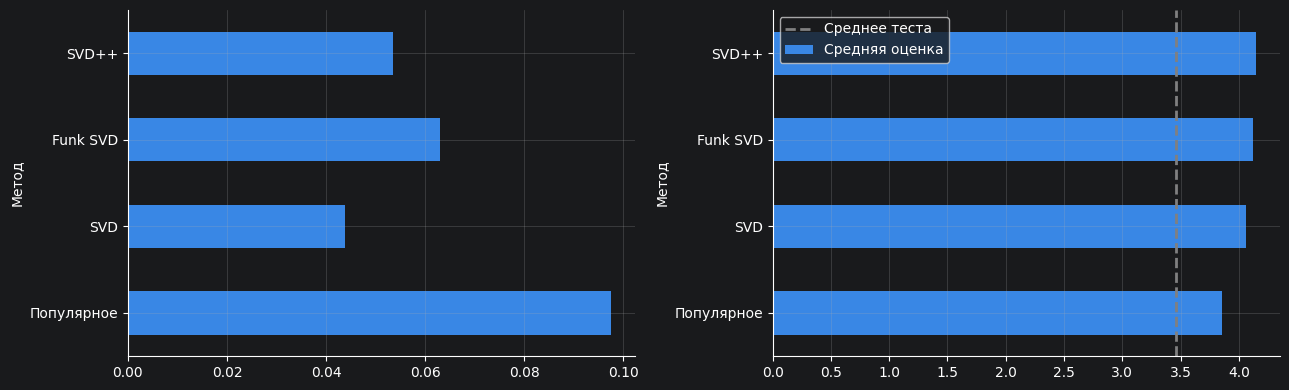

In [10]:
lookup = test.set_index(["userId", "movieId"])["rating"]
feedback_rows = []
for name, recs in test_recs.items():
    selected_pairs = [(u, m) for u in test["userId"].unique() for m in recs[u]]
    responses = lookup.reindex(pd.MultiIndex.from_tuples(selected_pairs))
    rated = responses.dropna()
    feedback_rows.append({"Метод": name, "Доля известных откликов": responses.notna().mean(),
                          "Откликов": len(rated), "Средняя оценка": rated.mean(),
                          "Доля положительных": (rated >= mc.RELEVANCE_THRESHOLD).mean() if len(rated) else np.nan})
feedback_table = pd.DataFrame(feedback_rows).set_index("Метод")
feedback_table.to_csv(RESULT_DIR / "retrospective_feedback.csv")
print(feedback_table.round(4).to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
feedback_table["Доля известных откликов"].plot.barh(ax=axes[0], color=MAIN_COLOR)
feedback_table["Средняя оценка"].plot.barh(ax=axes[1], color=MAIN_COLOR)
axes[1].axvline(test["rating"].mean(), color="gray", linestyle="--", label="Среднее теста"); axes[1].legend()
finish_figure("05_retrospective_feedback")


# Что означают скрытые факторы

Интерпретируем именно обычное SVD: выводим вклад $\sigma_f^2$, крайние фильмы по координате $q_{if}$ и связь фактора с жанрами. Для зрителя используем $p_{uf}$ и его средние **отклонения оценок от собственной средней** по жанрам.

Жанры используются после обучения для объяснения, а не для предсказания оценок. Знак фактора условен: одновременная смена знака столбцов $P$ и $Q$ не меняет прогноз. Названия факторов - предложения по интерпретации; фактор может описывать популярность, стиль оценивания или смесь тем и не обязан соответствовать одному жанру.



Фактор 1: положительный полюс
                                    title                 genres
movieId                                                         
115713                  Ex Machina (2015)  Drama|Sci-Fi|Thriller
106920                         Her (2013)   Drama|Romance|Sci-Fi
109374   Grand Budapest Hotel, The (2014)           Comedy|Drama
112552                    Whiplash (2014)                  Drama
112556                   Gone Girl (2014)         Drama|Thriller
Отрицательный полюс
                                              title                        genres
movieId                                                                          
122912       Avengers: Infinity War - Part I (2018)       Action|Adventure|Sci-Fi
122914      Avengers: Infinity War - Part II (2019)       Action|Adventure|Sci-Fi
89745                          Avengers, The (2012)  Action|Adventure|Sci-Fi|IMAX
110102   Captain America: The Winter Soldier (2014)  Action|Adventure|Sci-Fi|IMAX
12

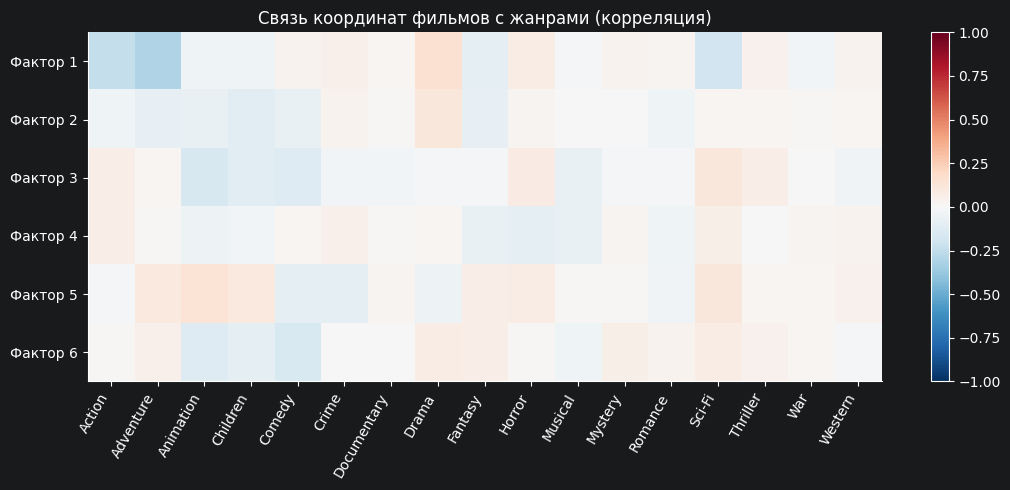

In [11]:
genre_names = [g for g in mc.GENRES if g != "IMAX" and g in movie_info.columns and movie_info[g].sum() >= 5]
G = movie_info[genre_names].to_numpy(float)
user_means = full["R"].sum(axis=1)/np.maximum(full["M"].sum(axis=1), 1)
genre_counts = full["M"].astype(float) @ G
genre_pref = ((full["R"]-user_means[:, None])*full["M"]) @ G
genre_pref = np.divide(genre_pref, genre_counts, out=np.full_like(genre_pref, np.nan), where=genre_counts >= 3)

def correlation(x, y):
    good = np.isfinite(x) & np.isfinite(y)
    if good.sum() < 3 or np.std(x[good]) < 1e-12 or np.std(y[good]) < 1e-12: return 0.
    return float(np.corrcoef(x[good], y[good])[0, 1])

P, Q = models["SVD"]["P"], models["SVD"]["Q"]
factor_rows = []
for f in range(min(6, best_rank)):
    film_corr = np.array([correlation(Q[:, f], G[:, j]) for j in range(len(genre_names))])
    user_corr = np.array([correlation(P[:, f], genre_pref[:, j]) for j in range(len(genre_names))])
    strongest = np.argsort(-np.abs(film_corr))[:3]
    row = {"Фактор": f+1, "sigma": s_full[f], "Доля энергии": s_full[f]**2/np.sum(s_full**2),
           "Связь с жанрами фильмов": "; ".join(f"{genre_names[j]} {film_corr[j]:+.2f}" for j in strongest),
           "Связь с предпочтениями зрителей": "; ".join(f"{genre_names[j]} {user_corr[j]:+.2f}" for j in np.argsort(-np.abs(user_corr))[:3])}
    positive = [genre_names[j] for j in np.argsort(-film_corr) if film_corr[j] >= .15][:3]
    negative = [genre_names[j] for j in np.argsort(film_corr) if film_corr[j] <= -.15][:3]
    row["Предложение интерпретации"] = ("Положительный полюс: " + (", ".join(positive) or "нет ясной жанровой связи")
                                        + "; отрицательный: " + (", ".join(negative) or "нет ясной жанровой связи"))
    factor_rows.append(row)
    print(f"\nФактор {f+1}: положительный полюс")
    print(movie_info.iloc[np.argsort(-Q[:, f])[:5]][["title", "genres"]].to_string())
    print("Отрицательный полюс")
    print(movie_info.iloc[np.argsort(Q[:, f])[:5]][["title", "genres"]].to_string())
factor_table = pd.DataFrame(factor_rows)
factor_table.to_csv(RESULT_DIR / "factor_interpretation.csv", index=False)
print(factor_table.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(11, 5))
corr_matrix = np.array([[correlation(Q[:, f], G[:, j]) for j in range(len(genre_names))] for f in range(min(6, best_rank))])
im = ax.imshow(corr_matrix, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(genre_names))); ax.set_xticklabels(genre_names, rotation=60, ha="right")
ax.set_yticks(range(len(corr_matrix))); ax.set_yticklabels([f"Фактор {f+1}" for f in range(len(corr_matrix))])
ax.set_title("Связь координат фильмов с жанрами (корреляция)"); ax.grid(False); plt.colorbar(im, ax=ax)
finish_figure("06_factor_genres")


# Кластеризация зрителей

Используем $P$ из итогового SVD - представление зрителя, полученное только из `train`. Стандартизируем координаты и нормируем длину вектора: сравниваем направление предпочтений, уменьшая влияние активности. Это преобразование применяется **только к кластеризации**, формулу прогноза оно не меняет. Сохраняем его параметры для нового зрителя.

Сравниваем все методы на **одних зрителях и одном пространстве признаков**. Диапазон числа кластеров - 3, 4, 6, 8 (ограничивается размером данных). Жанровые группы из работы №2 не являются истинными классами зрителей. Поэтому не называем совпадение с ними «точностью» кластеризации.

## EM для смеси нормальных распределений

Реализуем EM вручную на NumPy. E-шаг вычисляет ответственности
$$\gamma_{uc}=\frac{\pi_c\,\mathcal N(x_u\mid\mu_c,\Sigma_c)}{\sum_l\pi_l\,\mathcal N(x_u\mid\mu_l,\Sigma_l)},$$
M-шаг обновляет веса, центры и ковариации по этим ответственностям. Используем логарифмы и `logsumexp`, нижнюю границу дисперсии и несколько начальных приближений.

Число компонент смеси и число непустых групп после жёсткого назначения могут различаться. В таблице сохраняем и запрошенное `k`, и фактическое `n_clusters`; компоненту без назначенных зрителей не считаем отдельной пользовательской группой.

Сравниваем **диагональные** и **сферические** ковариации. У EM нет правила слияния кластеров: вероятности определяются плотностью распределения и соответствующим расстоянием Махаланобиса. При сферической ковариации оно пропорционально евклидову. Не подменяем EM произвольной заменой расстояния в формуле нормальной плотности. Для обеих полученных группировок ниже отдельно сравниваем межкластерные расстояния.


In [12]:
def transform_profiles(P, mean, scale):
    X = (P-mean)/scale
    return X/np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)


def gmm_posterior(X, weights, means, variances):
    # variances всегда имеет размер k × d, в том числе для сферической модели.
    d = X.shape[1]
    logp = np.empty((len(X), len(weights)))
    for c in range(len(weights)):
        logp[:, c] = (np.log(max(weights[c], 1e-300))-.5*(d*np.log(2*np.pi)
                      +np.log(variances[c]).sum()+((X-means[c])**2/variances[c]).sum(axis=1)))
    normalizer = logsumexp(logp, axis=1)
    return np.exp(logp-normalizer[:, None]), normalizer


def fit_gmm(X, k, covariance="diag", restarts=3, max_iter=150, tol=1e-5, seed=SEED):
    if covariance not in ("diag", "spherical"): raise ValueError(covariance)
    rng = np.random.default_rng(seed)
    best = None
    for run in range(restarts):
        # k-means++ и несколько шагов Ллойда служат только начальным приближением EM.
        selected = [int(rng.integers(len(X)))]
        for _ in range(k-1):
            dist = cdist(X, X[selected], metric="sqeuclidean").min(axis=1)
            selected.append(int(rng.choice(len(X), p=dist/dist.sum())) if dist.sum() > 0 else int(rng.integers(len(X))))
        means = X[selected].copy()
        for _ in range(8):
            labels = cdist(X, means).argmin(axis=1)
            means = np.array([X[labels == c].mean(axis=0) if (labels == c).any() else X[rng.integers(len(X))] for c in range(k)])
        weights = np.full(k, 1/k)
        var = np.tile(np.maximum(X.var(axis=0), 1e-4), (k, 1))
        if covariance == "spherical": var[:] = var.mean()
        history = []
        for _ in range(max_iter):
            resp, _ = gmm_posterior(X, weights, means, var)
            counts = resp.sum(axis=0)+1e-12
            weights = counts/counts.sum()
            means = resp.T @ X/counts[:, None]
            second = resp.T @ (X**2)/counts[:, None]-means**2
            if covariance == "spherical": second = np.repeat(second.mean(axis=1, keepdims=True), X.shape[1], axis=1)
            var = np.maximum(second, 1e-4)
            _, logp = gmm_posterior(X, weights, means, var)
            history.append(float(logp.mean()))
            if len(history) > 1 and abs(history[-1]-history[-2]) < tol: break
        resp, logp = gmm_posterior(X, weights, means, var)
        parameters = (k-1)+k*X.shape[1]+(k*X.shape[1] if covariance == "diag" else k)
        model = {"weights": weights, "means": means, "variances": var, "covariance": covariance,
                 "history": history, "bic": -2*logp.sum()+parameters*np.log(len(X)),
                 "labels": resp.argmax(axis=1), "responsibilities": resp}
        if best is None or history[-1] > best["history"][-1]: best = model
    return best


EM/diag/k=3 BIC -7806.1 итераций 79
EM/diag/k=4 BIC -7950.0 итераций 150
EM/diag/k=6 BIC -8040.8 итераций 84
EM/diag/k=8 BIC -8145.6 итераций 119
EM/spherical/k=3 BIC -7316.0 итераций 123
EM/spherical/k=4 BIC -7581.2 итераций 150
EM/spherical/k=6 BIC -7697.3 итераций 68
EM/spherical/k=8 BIC -8003.3 итераций 149
EM, выбор по BIC: EM/diag/k=8


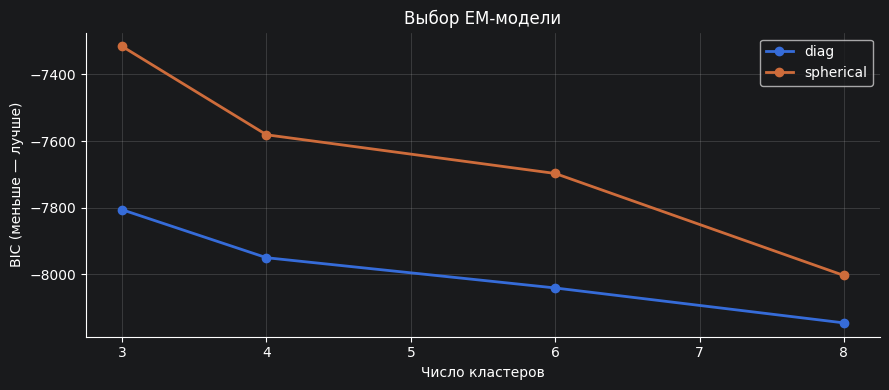

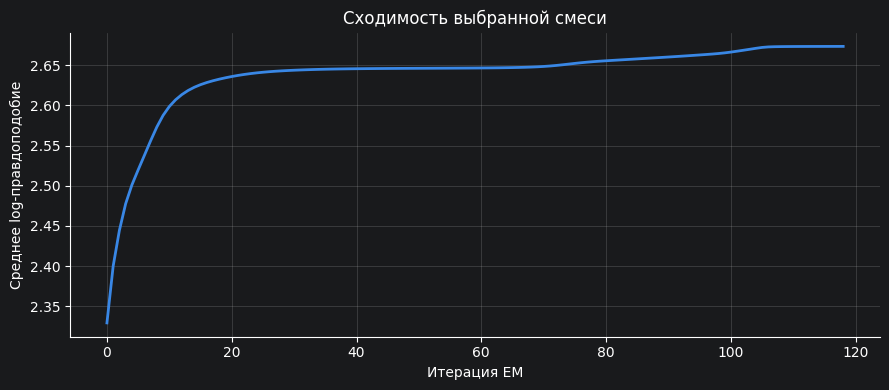

In [13]:
scaler = StandardScaler().fit(P)
X = transform_profiles(P, scaler.mean_, scaler.scale_)
K_CLUSTERS = [k for k in [3, 4, 6, 8] if k < len(X)]
if not K_CLUSTERS: raise ValueError("Для кластерного анализа нужно минимум 4 зрителя")
# Одна фиксированная подвыборка и одна евклидова матрица для всех силуэтов.
sample_idx = np.sort(np.random.default_rng(SEED).choice(len(X), min(800, len(X)), replace=False))
D_sample = squareform(pdist(X[sample_idx], metric="euclidean"))

def partition_metrics(labels):
    sizes = np.bincount(labels)
    sampled = labels[sample_idx]
    sil = silhouette_score(D_sample, sampled, metric="precomputed") if 1 < len(np.unique(sampled)) < len(sampled) else np.nan
    return {"silhouette": sil, "min_size": int(sizes[sizes > 0].min()),
            "max_share": sizes.max()/len(labels), "n_clusters": len(np.unique(labels))}

gmm_models, cluster_rows, partitions = {}, [], {}
for covariance in ["diag", "spherical"]:
    for k in K_CLUSTERS:
        key = f"EM/{covariance}/k={k}"
        model = fit_gmm(X, k, covariance)
        gmm_models[key] = model; partitions[key] = model["labels"]
        cluster_rows.append({"name": key, "family": "EM", "k": k, "metric": "Gaussian", "linkage": covariance,
                             "BIC": model["bic"], **partition_metrics(model["labels"])})
        print(key, "BIC", round(model["bic"], 1), "итераций", len(model["history"]))
best_gmm_name = min(gmm_models, key=lambda key: gmm_models[key]["bic"])
best_gmm = gmm_models[best_gmm_name]
assert np.allclose(best_gmm["responsibilities"].sum(axis=1), 1)
print("EM, выбор по BIC:", best_gmm_name)
plt.figure(figsize=(9, 4))
for covariance in ["diag", "spherical"]:
    keys = [f"EM/{covariance}/k={k}" for k in K_CLUSTERS]
    plt.plot(K_CLUSTERS, [gmm_models[key]["bic"] for key in keys], "o-", label=covariance)
plt.xlabel("Число кластеров"); plt.ylabel("BIC (меньше - лучше)"); plt.title("Выбор EM-модели"); plt.legend()
finish_figure("07_gmm_bic")
plt.figure(figsize=(9, 4)); plt.plot(best_gmm["history"], color=MAIN_COLOR)
plt.xlabel("Итерация EM"); plt.ylabel("Среднее log-правдоподобие"); plt.title("Сходимость выбранной смеси")
finish_figure("08_em_convergence")


## Иерархическая кластеризация и способы измерения близости

Используем проверенную реализацию агломерации `scipy.cluster.hierarchy.linkage`. Сначала каждый зритель - отдельный кластер. На каждом шаге объединяется ближайшая пара.

Для одной и той же пары множеств $C_a,C_b$:
- single - $\min_{x\in C_a,y\in C_b}d(x,y)$;
- complete - $\max d(x,y)$;
- average - среднее всех попарных расстояний;
- weighted - среднее расстояний от двух объединяемых кластеров с равными весами кластеров;
- centroid - расстояние между центрами;
- Ward - объединение с наименьшим приростом внутрикластерной суммы квадратов.

Сравниваем евклидово, манхэттенское и косинусное расстояния для single, complete, average и weighted. Для centroid и Ward используем **только евклидово** - остальные комбинации нарушают предпосылки этих способов. Дерево строится один раз для каждой комбинации, затем разрезается на несколько значений $k$.

Основной критерий сравнения - евклидов силуэт **в одном пространстве** для всех вариантов, а не разные силуэты в несопоставимых метриках. Также смотрим размеры групп: высокий силуэт при одной огромной группе и нескольких одиночках может быть непригоден для сегментации.


                            name    family  k    metric  linkage        BIC  silhouette  min_size  max_share  n_clusters
 Hierarchy/euclidean/average/k=6 Hierarchy  6 euclidean  average        NaN      0.0254       230     0.2973           6
 Hierarchy/euclidean/average/k=8 Hierarchy  8 euclidean  average        NaN      0.0252       129     0.1851           8
 Hierarchy/euclidean/average/k=4 Hierarchy  4 euclidean  average        NaN      0.0240       291     0.4572           4
 Hierarchy/euclidean/average/k=3 Hierarchy  3 euclidean  average        NaN      0.0229       299     0.4572           3
 Hierarchy/cityblock/average/k=3 Hierarchy  3 cityblock  average        NaN      0.0227       493     0.4764           3
    Hierarchy/cosine/average/k=3 Hierarchy  3    cosine  average        NaN      0.0226       308     0.4225           3
    Hierarchy/cosine/average/k=6 Hierarchy  6    cosine  average        NaN      0.0217       191     0.2264           6
    Hierarchy/cosine/average/k=4

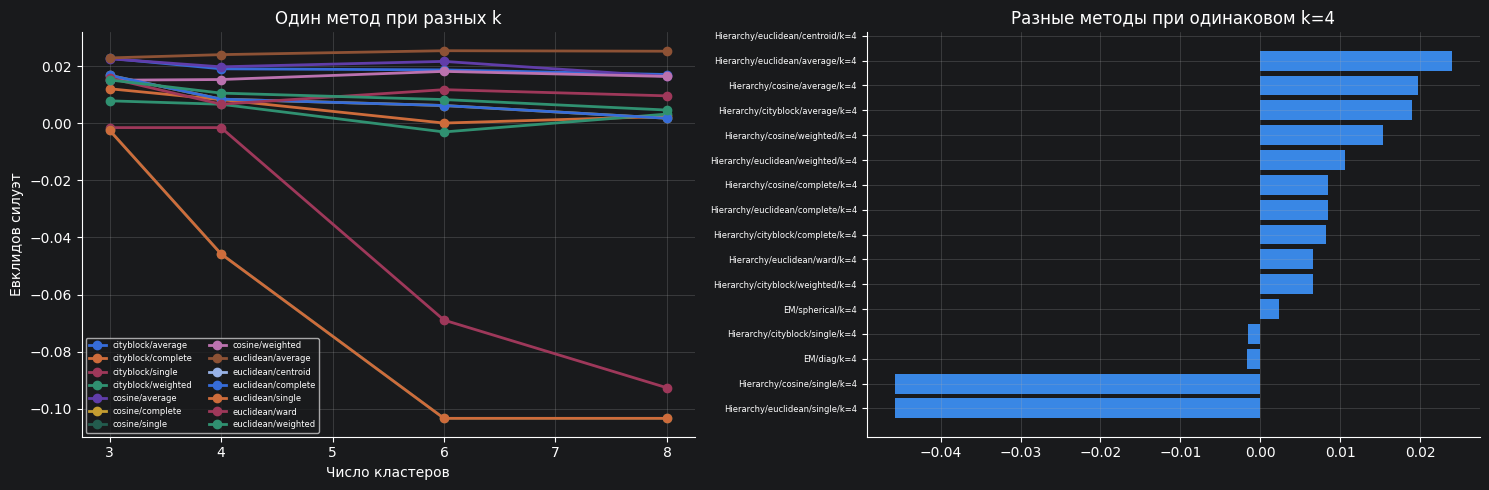

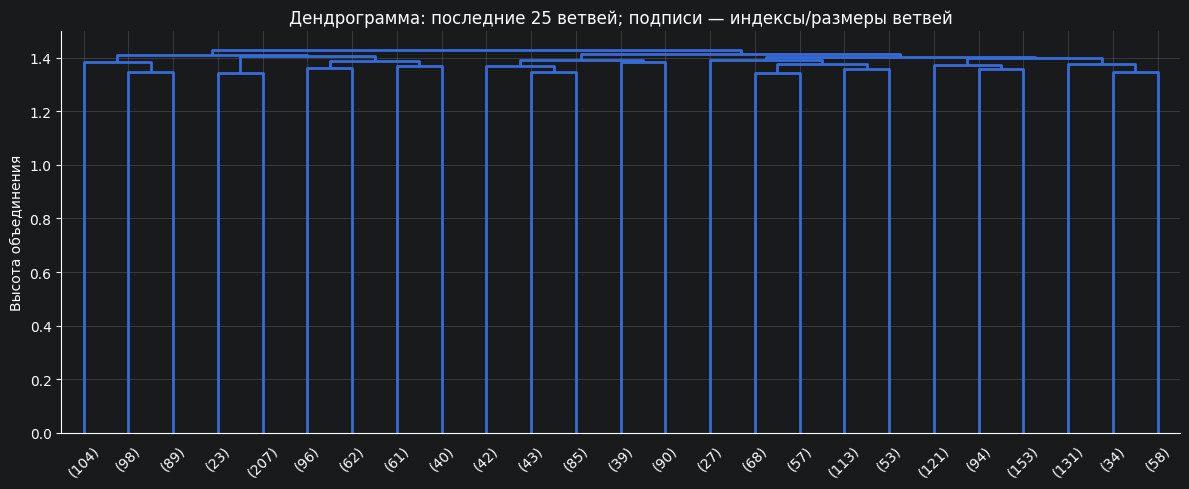

In [14]:
trees = {}
for metric in ["euclidean", "cityblock", "cosine"]:
    distances = pdist(X, metric=metric)
    # Нулевой профиль может дать NaN для cosine; договоримся d(0,x)=1, d(0,0)=0.
    if metric == "cosine" and not np.isfinite(distances).all():
        norm = np.linalg.norm(X, axis=1)
        cosine_matrix = 1-X @ X.T/np.maximum(norm[:, None]*norm[None, :], 1e-12)
        both_zero = (norm[:, None] == 0) & (norm[None, :] == 0)
        cosine_matrix[both_zero] = 0; np.fill_diagonal(cosine_matrix, 0)
        distances = squareform(np.clip(cosine_matrix, 0, 2), checks=False)
    methods = ["single", "complete", "average", "weighted"] + (["centroid", "ward"] if metric == "euclidean" else [])
    for method in methods:
        Z = linkage(distances, method=method)
        trees[(metric, method)] = Z
        labels_by_k = cut_tree(Z, n_clusters=K_CLUSTERS)
        for j, k in enumerate(K_CLUSTERS):
            key = f"Hierarchy/{metric}/{method}/k={k}"
            labels = labels_by_k[:, j]
            partitions[key] = labels
            cluster_rows.append({"name": key, "family": "Hierarchy", "k": k, "metric": metric,
                                 "linkage": method, "BIC": np.nan, **partition_metrics(labels)})
cluster_table = pd.DataFrame(cluster_rows)
cluster_table.to_csv(RESULT_DIR / "clustering_comparison.csv", index=False)
hierarchy_table = cluster_table[cluster_table["family"] == "Hierarchy"]
# Отдельно отмечаем пригодность сегментации, не прячем вырожденные варианты.
usable = hierarchy_table[(hierarchy_table["min_size"] >= max(2, int(.01*len(X)))) & (hierarchy_table["max_share"] <= .9)]
pool = usable if len(usable) else hierarchy_table
best_hierarchy_name = pool.loc[pool["silhouette"].idxmax(), "name"]
print(cluster_table.sort_values("silhouette", ascending=False).head(15).round(4).to_string(index=False))
print("Выбранная иерархия:", best_hierarchy_name)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for (metric, method), frame in hierarchy_table.groupby(["metric", "linkage"]):
    axes[0].plot(frame["k"], frame["silhouette"], marker="o", label=f"{metric}/{method}")
axes[0].set_xlabel("Число кластеров"); axes[0].set_ylabel("Евклидов силуэт"); axes[0].set_title("Один метод при разных k")
axes[0].legend(fontsize=6, ncol=2)
fixed_k = K_CLUSTERS[min(1, len(K_CLUSTERS)-1)]
fixed = cluster_table[cluster_table["k"] == fixed_k].sort_values("silhouette")
axes[1].barh(fixed["name"], fixed["silhouette"], color=MAIN_COLOR); axes[1].tick_params(axis="y", labelsize=6)
axes[1].set_title(f"Разные методы при одинаковом k={fixed_k}")
finish_figure("09_clustering_comparison")
best_row = cluster_table.set_index("name").loc[best_hierarchy_name]
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(trees[(best_row["metric"], best_row["linkage"])], truncate_mode="lastp", p=25, ax=ax)
ax.set_title("Дендрограмма: последние 25 ветвей; подписи - индексы/размеры ветвей")
ax.set_ylabel("Высота объединения")
finish_figure("10_dendrogram")


## Сравнение группировок и расстояний между кластерами

ARI и NMI показывают согласованность двух группировок одних и тех же зрителей; **это не точность относительно истинных классов**. Считаем их при одинаковом $k$, затем отдельно сравниваем выбранные решения с их собственным $k$.

Для обоих алгоритмов на фиксированных полученных кластерах считаем четыре определения межкластерного расстояния: ближайшие соседи, наиболее удалённые, среднее попарное и расстояние центров. Повторяем с евклидовой и манхэттенской метриками. Для EM это анализ уже полученного разбиения, а не замена E-шага. Внутри одного разбиения кластеры и их участники при смене определения расстояния остаются прежними.


 k   reference                           method    ARI   NMI
 4 EM/diag/k=4                      EM/diag/k=4  1.000 1.000
 4 EM/diag/k=4                 EM/spherical/k=4  0.490 0.531
 4 EM/diag/k=4   Hierarchy/euclidean/single/k=4 -0.002 0.001
 4 EM/diag/k=4 Hierarchy/euclidean/complete/k=4  0.080 0.149
 4 EM/diag/k=4  Hierarchy/euclidean/average/k=4  0.031 0.179
 4 EM/diag/k=4 Hierarchy/euclidean/weighted/k=4  0.040 0.118
 4 EM/diag/k=4 Hierarchy/euclidean/centroid/k=4  0.000 0.000
 4 EM/diag/k=4     Hierarchy/euclidean/ward/k=4  0.171 0.286
 4 EM/diag/k=4   Hierarchy/cityblock/single/k=4 -0.002 0.001
 4 EM/diag/k=4 Hierarchy/cityblock/complete/k=4  0.052 0.140
 4 EM/diag/k=4  Hierarchy/cityblock/average/k=4  0.029 0.152
 4 EM/diag/k=4 Hierarchy/cityblock/weighted/k=4  0.010 0.110
 4 EM/diag/k=4      Hierarchy/cosine/single/k=4 -0.002 0.001
 4 EM/diag/k=4    Hierarchy/cosine/complete/k=4  0.080 0.149
 4 EM/diag/k=4     Hierarchy/cosine/average/k=4 -0.017 0.115
 4 EM/diag/k=4    Hierar

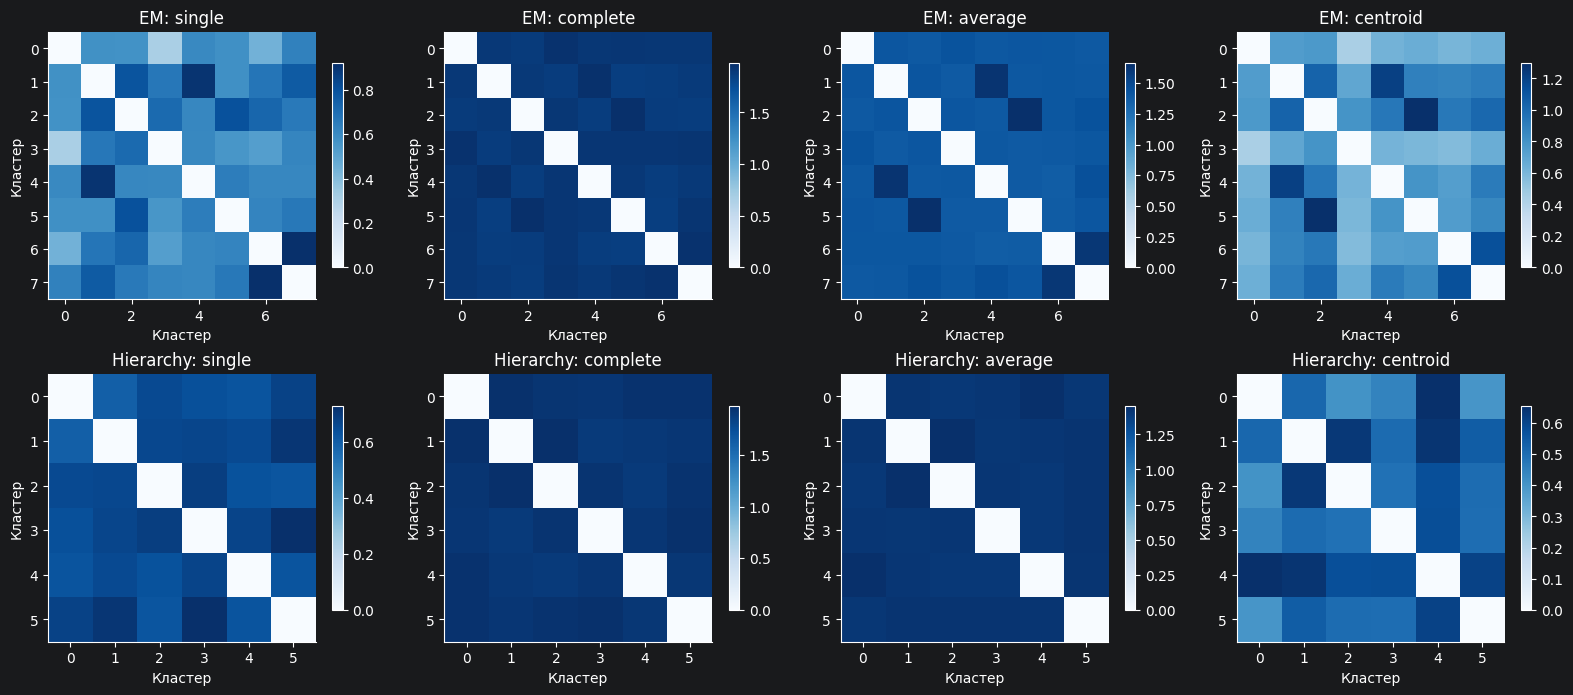

                     single  complete  average  centroid
family    metric                                        
EM        cityblock   2.241     7.314    5.134     2.803
          euclidean   0.642     1.907    1.433     0.810
Hierarchy cityblock   2.299     7.508    5.093     1.845
          euclidean   0.659     1.934    1.420     0.532
Средние расстояния служат описанием геометрии; их величина не является рейтингом качества метода.


In [15]:
agreement_rows = []
for k in K_CLUSTERS:
    keys = cluster_table.loc[cluster_table["k"] == k, "name"].tolist()
    reference = f"EM/diag/k={k}"
    for key in keys:
        agreement_rows.append({"k": k, "reference": reference, "method": key,
                               "ARI": adjusted_rand_score(partitions[reference], partitions[key]),
                               "NMI": normalized_mutual_info_score(partitions[reference], partitions[key])})
agreement = pd.DataFrame(agreement_rows)
agreement.to_csv(RESULT_DIR / "partition_agreement.csv", index=False)
print(agreement[agreement["k"] == fixed_k].round(3).to_string(index=False))
selected_labels = {"EM": partitions[best_gmm_name], "Hierarchy": partitions[best_hierarchy_name]}
print("Согласованность выбранных разбиений:", adjusted_rand_score(*selected_labels.values()))
distance_rows = []
for family, labels in selected_labels.items():
    groups = np.unique(labels)
    for metric in ["euclidean", "cityblock"]:
        for a in groups:
            for b in groups:
                if b <= a: continue
                Xa, Xb = X[labels == a], X[labels == b]
                dist = cdist(Xa, Xb, metric=metric)
                distance_rows.append({"family": family, "metric": metric, "a": a, "b": b,
                                      "single": dist.min(), "complete": dist.max(), "average": dist.mean(),
                                      "centroid": cdist(Xa.mean(axis=0, keepdims=True), Xb.mean(axis=0, keepdims=True), metric=metric)[0, 0]})
cluster_distances = pd.DataFrame(distance_rows)
cluster_distances.to_csv(RESULT_DIR / "intercluster_distances.csv", index=False)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for r, (family, labels) in enumerate(selected_labels.items()):
    k = int(labels.max())+1
    for c, method in enumerate(["single", "complete", "average", "centroid"]):
        matrix = np.zeros((k, k))
        rows = cluster_distances[(cluster_distances["family"] == family) & (cluster_distances["metric"] == "euclidean")]
        for row in rows.itertuples(): matrix[row.a, row.b] = matrix[row.b, row.a] = getattr(row, method)
        im = axes[r, c].imshow(matrix, cmap="Blues"); axes[r, c].grid(False)
        axes[r, c].set_title(f"{family}: {method}"); axes[r, c].set_xlabel("Кластер"); axes[r, c].set_ylabel("Кластер")
        plt.colorbar(im, ax=axes[r, c], shrink=.7)
finish_figure("11_intercluster_distances")
print(cluster_distances.groupby(["family", "metric"])[["single", "complete", "average", "centroid"]].mean().round(3))
print("Средние расстояния служат описанием геометрии; их величина не является рейтингом качества метода.")


## Смысл групп зрителей

Показываем число зрителей, отклонения их жанровых предпочтений и популярные понравившиеся фильмы внутри группы. По этим данным можно предложить названия сегментов, не приписывая зрителям возраст, пол или другие отсутствующие признаки.

Двумерный PCA-график служит иллюстрацией: все алгоритмы обучены в полном пространстве факторов, а не по двум нарисованным координатам.


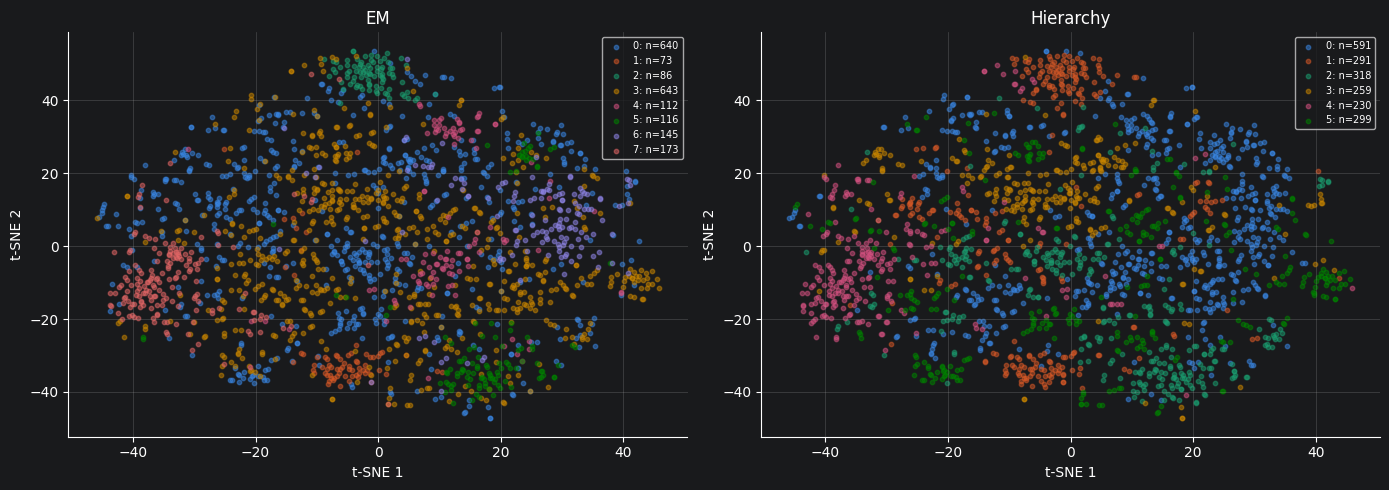

   family  cluster  viewers                                            genres                                                                                                                                                       popular_liked
       EM        0      640     Documentary +0.40; Drama +0.14; Western +0.13                                                                     Inception (2010); Arrival (2016); Parasite (2019); Interstellar (2014); Django Unchained (2012)
       EM        1       73     Western +0.33; Documentary +0.28; Drama +0.19                                                                         Interstellar (2014); Inception (2010); Parasite (2019); The Martian (2015); Whiplash (2014)
       EM        2       86 Documentary +0.53; Animation +0.08; Mystery +0.06                                                                       Parasite (2019); Knives Out (2019); Inception (2010); The Martian (2015); Interstellar (2014)
       EM        3      643     

In [23]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=SEED,
)
projection = tsne.fit_transform(X)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
profile_rows = []
for ax, (family, labels) in zip(axes, selected_labels.items()):
    for c in np.unique(labels):
        mask = labels == c
        ax.scatter(projection[mask, 0], projection[mask, 1], s=10, alpha=.5, color=PALETTE[c % len(PALETTE)], label=f"{c}: n={mask.sum()}")
        valid_counts = np.isfinite(genre_pref[mask]).sum(axis=0)
        prefs = np.divide(np.nansum(genre_pref[mask], axis=0), valid_counts, out=np.zeros(len(genre_names)), where=valid_counts > 0)
        supported = np.flatnonzero(valid_counts >= max(2, int(.1*mask.sum())))
        strongest = supported[np.argsort(-prefs[supported])[:3]]
        liked = ((full["R"][mask] >= mc.RELEVANCE_THRESHOLD) & full["M"][mask]).sum(axis=0)
        titles = movie_info.iloc[np.argsort(-liked)[:5]]["title"].tolist()
        profile_rows.append({"family": family, "cluster": c, "viewers": int(mask.sum()),
                             "genres": "; ".join(f"{genre_names[j]} {prefs[j]:+.2f}" for j in strongest),
                             "popular_liked": "; ".join(titles)})
    ax.set_title(family)
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.legend(fontsize=7)
finish_figure("12_viewer_clusters")
profiles = pd.DataFrame(profile_rows)
profiles.to_csv(RESULT_DIR / "cluster_profiles.csv", index=False)
print(profiles.to_string(index=False))
# Сохраняем соответствие конкретных зрителей группам.
pd.DataFrame({"userId": user_ids, **selected_labels}).to_csv(RESULT_DIR / "viewer_clusters.csv", index=False)


# Пример рекомендаций для одного зрителя

Для наглядности берём первого зрителя по идентификатору, не выбирая его по успешности на тесте. Показываем прошлые оценки, рекомендации и фактический отложенный отклик, если он известен.


In [17]:
example_user = user_ids[0]
past = train_full[train_full["userId"] == example_user].sort_values("timestamp").tail(10)
print("История зрителя", example_user)
print(past.merge(movies[["movieId", "title"]], on="movieId")[["title", "rating"]].to_string(index=False))
for name in models:
    print("\n", name)
    for movie_id in test_recs[name][example_user]:
        observed = lookup.get((example_user, movie_id), np.nan)
        text = f"оценка затем: {observed:.1f}" if np.isfinite(observed) else "отклик неизвестен"
        print(movie_info.loc[movie_id, "title"], "-", text)


История зрителя 258
                                                  title  rating
                                    Dark Shadows (2012)     5.0
                                   Frankenweenie (2012)     3.5
     Miss Peregrine's Home for Peculiar Children (2016)     3.5
                             Beautiful Creatures (2013)     2.0
                                        Parasite (2019)     4.0
                                  A Simple Favor (2018)     2.0
                                            Soul (2020)     5.0
                                           Tenet (2020)     4.0
Birdman: Or (The Unexpected Virtue of Ignorance) (2014)     4.5
                     Scott Pilgrim vs. the World (2010)     4.0

 SVD
Inception (2010) — отклик неизвестен
Planet Earth II (2016) — отклик неизвестен
Spider-Man: Into the Spider-Verse (2018) — отклик неизвестен
Blue Planet II (2017) — отклик неизвестен
Your Name. (2016) — отклик неизвестен
Over the Garden Wall (2013) — отклик неизвестен
A

# Сохранение моделей для демонстрации

Сохраняем **те же модели**, которые проверены выше: данные теста не добавляем при экспорте. Каталог, история обучения и параметры преобразований входят в файл; для запуска демонстрации достаточно `work3_svd.py` и этого `.npz`. Python-объекты через pickle не используются.

Новый зритель получает факторы через регуляризованное решение по своим оценкам при фиксированных факторах фильмов (fold-in). Неявный профиль SVD++ строится по всем введённым взаимодействиям, включая фильмы без оценки. Сначала можно вводить историю, затем отдельно оценивать предложенные фильмы - эти новые отзывы не подмешиваются в уже показанный прогноз.


In [18]:
export = {"format_version": np.array(1), "movie_ids": movie_ids,
          "titles": movie_info["title"].to_numpy(str),
          "genres": movie_info["genre_list"].apply("|".join).to_numpy(str),
          "popularity": full["popularity"], "user_ids": user_ids,
          "cluster_mean": scaler.mean_, "cluster_scale": scaler.scale_,
          "gmm_weights": best_gmm["weights"], "gmm_means": best_gmm["means"], "gmm_variances": best_gmm["variances"],
          "gmm_labels": best_gmm["labels"],
          "hier_centers": np.array([X[selected_labels["Hierarchy"] == c].mean(axis=0) for c in np.unique(selected_labels["Hierarchy"])]),
          "svd_singular_values": s_full[:best_rank], "svd_energy_total": np.array(np.sum(s_full**2))}
for j, (name, model) in enumerate(models.items()):
    prefix = f"m{j}_"
    for key in ["mu", "bu", "bi", "P", "Q"] + (["Y"] if name == "SVD++" else []): export[prefix+key] = np.asarray(model[key])
    export[prefix+"name"] = np.array(name)
    export[prefix+"reg"] = np.array(float(model.get("reg", 10.0)))
model_path = mc.DATA_DIR / "work3_models.npz"
np.savez_compressed(model_path, **export)
metadata = {"svd_rank": best_rank, "mf_configs": best_configs, "gmm": best_gmm_name, "hierarchy": best_hierarchy_name,
            "seed": SEED, "n_users": n_users, "n_movies": n_movies,
            "train_ratings": len(train_full), "test_ratings": len(test),
            "selection": "validation MAE; GMM BIC; hierarchy silhouette with cluster size checks"}
(RESULT_DIR / "configuration.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
print("Сохранено:", model_path)
print("Демонстрация: python work3_svd.py")
print("Без ввода:    python work3_svd.py --demo")


Сохранено: data\work3_models.npz
Демонстрация: python work3_svd.py
Без ввода:    python work3_svd.py --demo


# Новые оценки пользователей и выводы

После интерактивной проверки программа предложит оценить знакомые фильмы из выдачи. Если фильм неизвестен, его нужно пропустить: оценку не придумываем. Полученные отзывы сохраняются в `data/work3_feedback.csv` отдельно от исходного MovieLens. По ним можно оценить MAE именно на оценённых рекомендациях и долю понравившихся, но нельзя честно измерить полноту по всему неизвестному каталогу.

Если отзывов пока нет, соответствующий пункт остаётся открытым: ретроспективные тестовые оценки не объявляем новым пользовательским экспериментом.


In [19]:
feedback_path = mc.DATA_DIR / "work3_feedback.csv"
if feedback_path.exists():
    real_feedback = pd.read_csv(feedback_path)
    real_feedback["abs_error"] = abs(real_feedback["rating"]-real_feedback["prediction"])
    real_feedback["positive"] = real_feedback["rating"] >= mc.RELEVANCE_THRESHOLD
    print("Новые пользовательские оценки (отдельно от теста MovieLens):")
    print(real_feedback.groupby("method").agg(Отзывы=("rating", "size"), Сессии=("session", "nunique"),
          MAE=("abs_error", "mean"), Средняя_оценка=("rating", "mean"), Доля_положительных=("positive", "mean")).round(4))
else:
    print("Новых отзывов пока нет. Выполните интерактивный work3_svd.py и оцените знакомые фильмы из выдачи.")

best_mae = summary["MAE"].idxmin()
best_ndcg = summary["NDCG@10"].idxmax()
print(f"Минимальная тестовая MAE: {best_mae} ({summary.loc[best_mae, 'MAE']:.4f}).")
print(f"Максимальная тестовая NDCG@10: {best_ndcg} ({summary.loc[best_ndcg, 'NDCG@10']:.4f}).")
print(f"Выбранный ранг обычного SVD: {best_rank}; доля энергии {np.sum(s_full[:best_rank]**2)/np.sum(s_full**2):.1%}.")
for kind, config in best_configs.items():
    print(f"{kind}: rank={config['rank']}, lambda={config['reg']:g}, эпох={config['epochs']}.")
print("EM:", best_gmm_name, "; иерархия:", best_hierarchy_name)
for kind, config in best_configs.items():
    same_rank = mf_tuning[(mf_tuning["Метод"] == kind) & (mf_tuning["rank"] == config["rank"])]
    no_reg = float(same_rank.loc[same_rank["reg"] == 0, "MAE"].iloc[0])
    reg_only = same_rank[same_rank["reg"] > 0]
    reg_best = float(reg_only["MAE"].min())
    print(f"{kind}, одинаковый rank={config['rank']}: MAE valid без регуляризации {no_reg:.4f}, с лучшей положительной lambda {reg_best:.4f}.")
    print("Регуляризация улучшила отложенную ошибку." if reg_best < no_reg else "В этом сравнении регуляризация не улучшила отложенную MAE; её пользу нельзя утверждать по одной train-кривой.")
for family, labels in selected_labels.items():
    sizes = np.bincount(labels)
    sizes = sizes[sizes > 0]
    print(f"{family}: {len(sizes)} групп; от {sizes.min()} до {sizes.max()} зрителей; крупнейшая группа {sizes.max()/len(labels):.1%}.")
single_rows = hierarchy_table[hierarchy_table["linkage"] == "single"]
print(f"Single linkage: максимальная доля крупнейшего кластера среди исследованных вариантов {single_rows['max_share'].max():.1%}; проверяем эффект цепочки, а не выбираем метод только по силуэту.")
same_k_agreement = agreement[(agreement["k"] == fixed_k) & (agreement["method"] != agreement["reference"])]
print(f"При k={fixed_k} согласованность с EM/diag по ARI меняется от {same_k_agreement['ARI'].min():.3f} до {same_k_agreement['ARI'].max():.3f}: смена метода может менять состав групп.")
print("Для одних и тех же кластеров single учитывает ближайшую пару, complete - крайний разброс, average - все пары, centroid - положение центров; поэтому их числа описывают разные свойства, а не разное качество рекомендаций.")
print("Проверка завершена. Вывод о полезности требует сравнения с ориентирами и анализа таблиц, а не только минимальной ошибки.")


Новых отзывов пока нет. Выполните интерактивный work3_svd.py и оцените знакомые фильмы из выдачи.
Минимальная тестовая MAE: SVD++ (0.5927).
Максимальная тестовая NDCG@10: Funk SVD (0.0639).
Выбранный ранг обычного SVD: 20; доля энергии 19.5%.
Funk SVD: rank=20, lambda=10, эпох=42.
SVD++: rank=10, lambda=10, эпох=119.
EM: EM/diag/k=8 ; иерархия: Hierarchy/euclidean/average/k=6
Funk SVD, одинаковый rank=20: MAE valid без регуляризации 0.6081, с лучшей положительной lambda 0.6027.
Регуляризация улучшила отложенную ошибку.
SVD++, одинаковый rank=10: MAE valid без регуляризации 0.6220, с лучшей положительной lambda 0.6037.
Регуляризация улучшила отложенную ошибку.
EM: 8 групп; от 73 до 643 зрителей; крупнейшая группа 32.3%.
Hierarchy: 6 групп; от 230 до 591 зрителей; крупнейшая группа 29.7%.
Single linkage: максимальная доля крупнейшего кластера среди исследованных вариантов 99.9%; проверяем эффект цепочки, а не выбираем метод только по силуэту.
При k=4 согласованность с EM/diag по ARI меня